# Sieci Kohonena - Grid

In [1]:
import numpy as np
import pandas as pd
import math
from tqdm import tqdm
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import plotly.express as px
import matplotlib.patches as patches
from collections import Counter
from plotly.subplots import make_subplots
import itertools

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

In [3]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))
        d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2
        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in range(self.iteracje):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [4]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [5]:
def wykres_2d_ax(model, dane_2d, etykiety, ax, tytul):
    scatter = ax.scatter(dane_2d[:, 0], dane_2d[:, 1], 
                         c=etykiety.flatten(), cmap='tab10', alpha=0.4)
    
    wx = model.wagi[:, :, 0]
    wy = model.wagi[:, :, 1]

    ax.scatter(wx.flatten(), wy.flatten(), c='red', marker='o', s=50, edgecolors='black', zorder=5)

    for i in range(model.M):
        ax.plot(wx[i, :], wy[i, :], c='black', alpha=0.6, linewidth=1.5)
    for j in range(model.N):
        ax.plot(wx[:, j], wy[:, j], c='black', alpha=0.6, linewidth=1.5)

    ax.set_title(tytul)
    ax.grid(True, linestyle='--', alpha=0.5)

In [6]:
def wykres_3d_ax(fig, model, data, etykiety, row, col, pokaz_legende):
    etykiety_plaskie = etykiety.flatten()
    unikalne_klasy = np.unique(etykiety_plaskie)
    kolory = px.colors.qualitative.D3 

    for i, klasa in enumerate(unikalne_klasy):
        idx = (etykiety_plaskie == klasa)
        fig.add_trace(go.Scatter3d(
            x=data[idx, 0], y=data[idx, 1], z=data[idx, 2],
            mode='markers', marker=dict(size=2, color=kolory[i % len(kolory)], opacity=0.3),
            name=f'Klasa {klasa}', showlegend=pokaz_legende
        ), row=row, col=col)

    wx, wy, wz = model.wagi[:, :, 0], model.wagi[:, :, 1], model.wagi[:, :, 2]

    fig.add_trace(go.Scatter3d(
        x=wx.flatten(), y=wy.flatten(), z=wz.flatten(),
        mode='markers', marker=dict(size=4, color='red', line=dict(color='black', width=1)),
        name='Neurony', showlegend=pokaz_legende
    ), row=row, col=col)

    for i in range(model.M):
        fig.add_trace(go.Scatter3d(x=wx[i, :], y=wy[i, :], z=wz[i, :], mode='lines', line=dict(color='black', width=1), showlegend=False, opacity=0.5), row=row, col=col)
    for j in range(model.N):
        fig.add_trace(go.Scatter3d(x=wx[:, j], y=wy[:, j], z=wz[:, j], mode='lines', line=dict(color='black', width=1), showlegend=False, opacity=0.5), row=row, col=col)

In [7]:
def mapping_plot_ax(model, dane, etykiety, ax, tytul):
    neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
    etykiety_plaskie = etykiety.flatten()
    
    for idx, x in enumerate(dane):
        bmu_coord = model.znajdz_najblizszy(x)
        neurony_klasy[bmu_coord].append(etykiety_plaskie[idx])
        
    cmap = plt.get_cmap('tab10')
    poprawne_trafienia = 0
    wszystkie_probki = len(dane)
    
    for i in range(model.M):
        for j in range(model.N):
            klasy_w_neuronie = neurony_klasy[(i, j)]
            liczba_punktow = len(klasy_w_neuronie)
            
            if liczba_punktow > 0:
                dominujaca_klasa, liczba_w_dominujacej = Counter(klasy_w_neuronie).most_common(1)[0]
                poprawne_trafienia += liczba_w_dominujacej
                kolor_tla = cmap(dominujaca_klasa)
                alpha_tla = 0.3
            else:
                kolor_tla, alpha_tla = 'white', 1.0
                
            rect = patches.Rectangle((i - 0.5, j - 0.5), 1, 1, linewidth=1, edgecolor='black', facecolor=kolor_tla, alpha=alpha_tla)
            ax.add_patch(rect)
            
            if liczba_punktow > 0:
                jx, jy = np.random.uniform(-0.35, 0.35, liczba_punktow), np.random.uniform(-0.35, 0.35, liczba_punktow)
                kolory_kropek = [cmap(k) for k in klasy_w_neuronie]
                ax.scatter(i + jx, j + jy, c=kolory_kropek, edgecolors='black', s=20, zorder=5)

    accuracy = poprawne_trafienia / wszystkie_probki
    
    ax.set_xlim(-0.5, model.M - 0.5)
    ax.set_ylim(-0.5, model.N - 0.5)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    
    ax.set_title(f"{tytul}\nAcc: {accuracy*100:.1f}%", fontweight='bold')
    ax.grid(False)
    
    return accuracy

In [8]:
def train_grid(data, y_etykiety, n, NM_lista, sigma_lista, funkcje, ncols, epoki=100, wygaszanie=50):
    modele = []
    df_dane = []

    kombinacje = list(itertools.product(funkcje, sigma_lista, NM_lista))
    calkowita_liczba_modeli = len(kombinacje)
        
    pasek_postepu = tqdm(kombinacje, total=calkowita_liczba_modeli, desc="Trening", unit="model")
    
    for funkcja, sig, nm in pasek_postepu:
                nazwa_funkcji = funkcja.__name__ 
                tytul = f"{nm}x{nm} | Sigma={sig} | {nazwa_funkcji}"
                
                model = Kohonen(nm, nm, n, epoki, sig, funkcja, wygaszanie)
                model.train(data)
                
                modele.append({
                    'nm': nm, 'sig': sig, 'funkcja': nazwa_funkcji, 
                    'tytul': tytul, 'model': model
                })

    liczba_modeli = len(modele)
    cols = min(ncols, liczba_modeli)
    rows = math.ceil(liczba_modeli / cols)
    
    if n == 2:
        fig_dop, axes_dop = plt.subplots(rows, cols, figsize=(cols*4.5, rows*4.5))
        axes_dop = np.atleast_1d(axes_dop).flatten()
        
        for idx, m in enumerate(modele):
            wykres_2d_ax(m['model'], data, y_etykiety, axes_dop[idx], m['tytul'])
            
        for j in range(liczba_modeli, len(axes_dop)):
            axes_dop[j].axis('off')
            
        plt.tight_layout()
        plt.show()
        
    elif n == 3:
        specs = [[{'type': 'scene'} for _ in range(cols)] for _ in range(rows)]
        fig_3d = make_subplots(rows=rows, cols=cols, specs=specs, subplot_titles=[m['tytul'] for m in modele])
        
        for idx, m in enumerate(modele):
            r = (idx // cols) + 1
            c = (idx % cols) + 1
            wykres_3d_ax(fig_3d, m['model'], data, y_etykiety, r, c, pokaz_legende=(idx==0))
            
        fig_3d.update_layout(height=rows*350, width=cols*350, title_text="Dopasowanie Siatki Kohonena (3D)")
        fig_3d.show()

    fig_map, axes_map = plt.subplots(rows, cols, figsize=(cols*4.5, rows*4.5))
    axes_map = np.atleast_1d(axes_map).flatten()
    
    for idx, m in enumerate(modele):
        acc = mapping_plot_ax(m['model'], data, y_etykiety, axes_map[idx], m['tytul'])
        
        df_dane.append({
            'Rozmiar': f"{m['nm']}x{m['nm']}",
            'Sigma': m['sig'],
            'Funkcja': m['funkcja'],
            'Accuracy (%)': round(acc * 100, 2)
        })
        
    for j in range(liczba_modeli, len(axes_map)):
        axes_map[j].axis('off')
        
    plt.tight_layout()
    plt.show()
    
    df = pd.DataFrame(df_dane)
    df = df.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
    return df

In [9]:
def plot_neighborhood_functions(sigma_values, max_d=10):
    d = np.linspace(0, max_d, 300)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    for sigma in sigma_values:
        gauss = funkcja_Gaussa(d**2, sigma)
        mex   = meksykanski_kapelusz(d**2, sigma)
        axes[0].plot(d, gauss, label=f'sigma={sigma}')
        axes[1].plot(d, mex,   label=f'sigma={sigma}')
    
    axes[0].set_title('Funkcja Gaussowska')
    axes[0].set_xlabel('Odległość od BMU w siatce')
    axes[0].set_ylabel('h(d, sigma)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_title('Meksykański kapelusz')
    axes[1].set_xlabel('Odległość od BMU w siatce')
    axes[1].axhline(0, color='k', lw=0.5)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Dane hexagon

In [10]:
hexagon = pd.read_csv("mio2/hexagon.csv")

hexagon_data = hexagon[['x', 'y']].to_numpy() 
y_etykiety = hexagon[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = hexagon_data.shape[1]

In [11]:
NM = [4, 6, 10]
sigma = [0.1, 0.4, 0.7, 1, 2, 4, 6, 8]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]

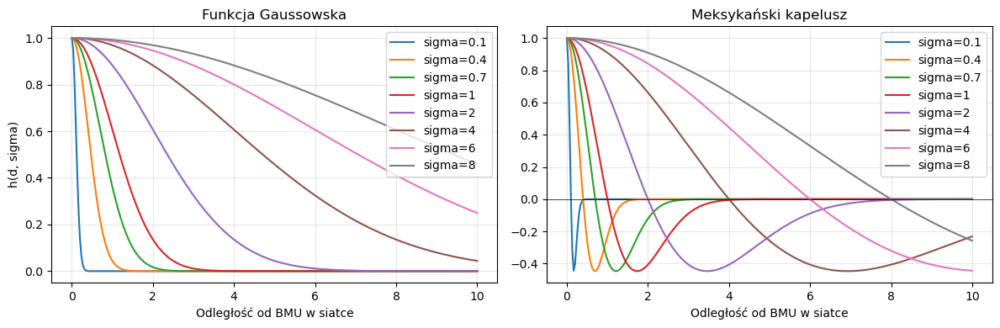

In [12]:
plot_neighborhood_functions(sigma)

Trening: 100%|██████████| 48/48 [01:44<00:00,  2.18s/model]


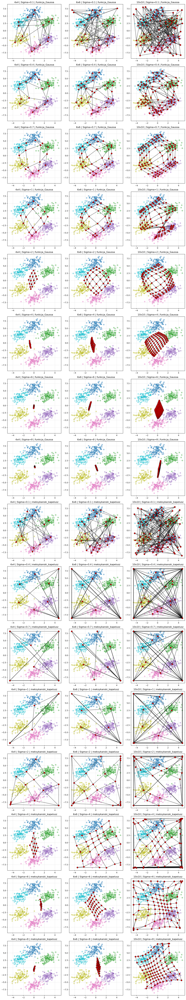

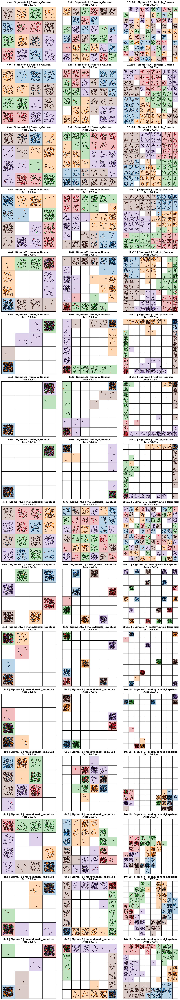

,Rozmiar,Sigma,Funkcja,Accuracy (%)
0,10x10,2.0,funkcja_Gaussa,98.67
1,10x10,0.4,funkcja_Gaussa,98.50
2,10x10,1.0,funkcja_Gaussa,98.17
3,10x10,0.1,funkcja_Gaussa,98.00
4,6x6,0.4,funkcja_Gaussa,98.00
5,10x10,4.0,funkcja_Gaussa,97.83
6,10x10,0.1,meksykanski_kapelusz,97.83
7,10x10,0.4,meksykanski_kapelusz,97.83
8,10x10,8.0,meksykanski_kapelusz,97.67
9,4x4,0.4,funkcja_Gaussa,97.67


In [13]:
train_grid(hexagon_data, y_etykiety, n, NM, sigma, funkcje, 3)

# Dane cube

In [14]:
cube = pd.read_csv("mio2/cube.csv")

cube_data = cube[['x', 'y', 'z']].to_numpy() 
y_etykiety = cube[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = cube_data.shape[1]

In [15]:
NM = [4, 6, 10]
sigma = [0.1, 0.4, 0.7, 1, 2, 4, 6, 8]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]

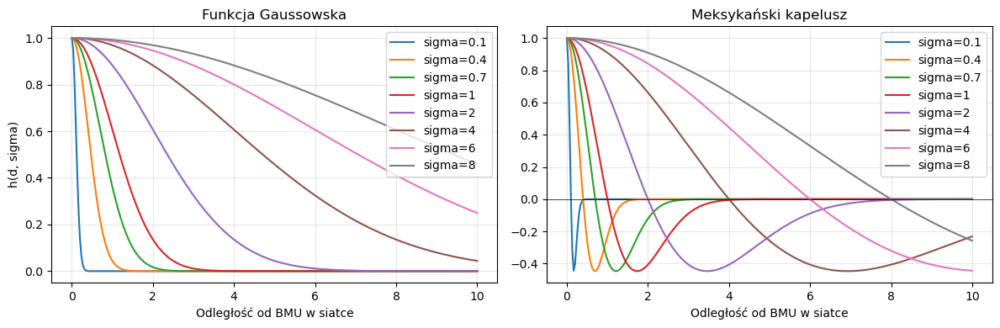

In [16]:
plot_neighborhood_functions(sigma)

Trening: 100%|██████████| 48/48 [04:49<00:00,  6.04s/model]


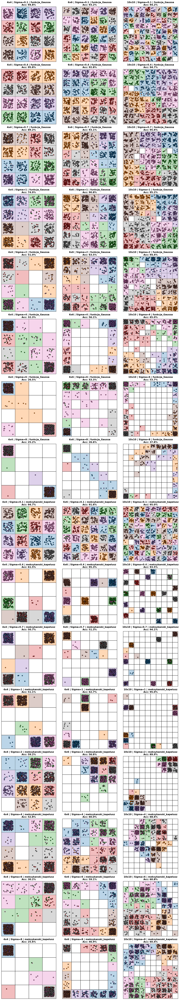

,Rozmiar,Sigma,Funkcja,Accuracy (%)
0,4x4,0.4,funkcja_Gaussa,95.83
1,10x10,0.7,funkcja_Gaussa,95.58
2,6x6,0.4,meksykanski_kapelusz,95.33
3,10x10,1.0,funkcja_Gaussa,95.17
4,10x10,1.0,meksykanski_kapelusz,95.00
5,10x10,0.1,meksykanski_kapelusz,95.00
6,4x4,0.1,funkcja_Gaussa,94.83
7,4x4,0.1,meksykanski_kapelusz,94.67
8,10x10,0.4,funkcja_Gaussa,94.67
9,10x10,2.0,funkcja_Gaussa,94.42


In [17]:
train_grid(cube_data, y_etykiety, n, NM, sigma, funkcje, 3)